# O25 quick start: one spectrum

This notebook guides a first O25 calculation. No knowledge of classes or internal lookup tables is required. The normal interface is simply `o25.correct(...)`.

We use one spectrum containing the first 12 OLCI bands. O25 corrects the input remote-sensing reflectance, and BH4 supplies uncertainty automatically because the target geometry defaults to `(0, 0, 0)`.

**Geometry order:** `(solar zenith, viewing zenith, relative azimuth)`, in degrees.


In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

# Locate the O25 repository automatically.
here = Path.cwd().resolve()
repository = next(
    (
        folder
        for folder in (here, *here.parents)
        if (folder / "o25" / "__init__.py").exists()
    ),
    None,
)

if repository is None:
    raise RuntimeError(
        "The O25 repository could not be found. "
        "Open this notebook from inside the downloaded O25 repository."
    )

# Make the local O25 package available without installation.
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))
import o25
data_file = repository / "examples" / "data" / "olci_spectrum.csv"
print("O25 is ready.")

O25 is ready.


## Read the spectrum

The CSV has two columns: wavelength in nanometres and above-water `Rrs` in sr⁻¹.


In [3]:
data = np.loadtxt(data_file, delimiter=",", skiprows=1)
wl, Rrs = data[:, 0], data[:, 1]
print("Number of bands:", wl.size)
print("Wavelengths [nm]:", wl)


Number of bands: 12
Wavelengths [nm]: [400. 412. 443. 490. 510. 560. 620. 665. 673. 681. 709. 753.]


## Correct the observation

The source geometry below means solar zenith 30°, viewing zenith 20°, and relative azimuth 120°. Because `g1` is omitted, O25 uses target geometry `(0, 0, 0)`.


In [4]:
g0 = (30, 20, 120)
r = o25.correct(wl, Rrs, g0)

print("BH4 class:", r.k)
print("Uncertainty probability:", r.p)
print("Uncertainty status:", r.uncertainty_status)


BH4 class: 4
Uncertainty probability: 0.68
Uncertainty status: available_native_olci


## Plot corrected Rrs with uncertainty bars

The vertical bars are the **dimensional BH4 uncertainty in the same units as Rrs**. O25 calculates these values as `u = u_rel × |Rrs corrected|`.

The default probability is `p = 0.68`. These empirical bounds should not automatically be described as one standard deviation.


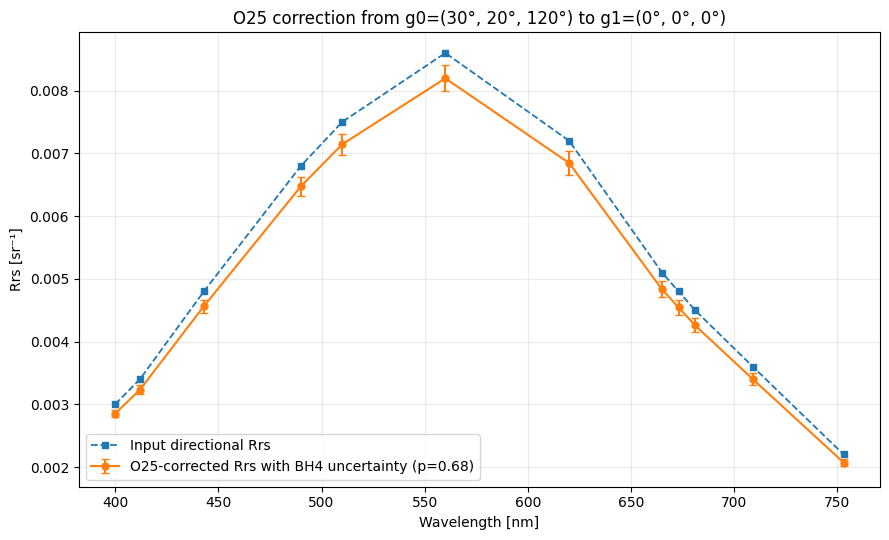

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(wl, Rrs, "s--", linewidth=1.3, markersize=5, label="Input directional Rrs")
ax.errorbar(
    wl, r.Rrs, yerr=r.u,
    fmt="o-", linewidth=1.5, markersize=5, capsize=3,
    label=f"O25-corrected Rrs with BH4 uncertainty (p={r.p:g})",
)
ax.set_xlabel("Wavelength [nm]")
ax.set_ylabel("Rrs [sr⁻¹]")
ax.set_title("O25 correction from g0=(30°, 20°, 120°) to g1=(0°, 0°, 0°)")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## Save the result

The output keeps the input wavelength order. `uncertainty` is expressed in sr⁻¹, like corrected Rrs.


In [ ]:
out = np.column_stack((wl, Rrs, r.Rrs, r.u))
out_file = data_file.with_name("olci_result.csv")
np.savetxt(out_file, out, delimiter=",",
           header="wavelength_nm,Rrs_input,Rrs_corrected,uncertainty", comments="")
print("Saved:", out_file)
